# ML bacteria
使用Machine Learning对bacteria中finetune数据集进行训练并预测test数据集。
## 1 使用原始数据进行训练预测

In [24]:
import numpy as np

# 载入finetune数据集
X_f = './data/X_finetune.npy'
y_f = './data/y_finetune.npy'
X_train = np.load(X_f)  # 微调(finetune)训练集：拉曼光谱数据，每行是一条光谱
y_train = np.load(y_f)  # 训练集标签（菌株类别编号）

X_f = './data/X_test.npy'
y_f = './data/y_test.npy'
X_test = np.load(X_f)  # 测试集光谱
y_test = np.load(y_f)  # 测试集标签

In [25]:
from sklearn.model_selection import cross_validate  # 导入交叉验证
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
# 准备工作：导入 SVM 分类器、交叉验证与常用评估指标

In [4]:
# 使用SVM模型
svm_clf = SVC(kernel='linear')
# 进行交叉验证并返回每个折中的模型
cv_results = cross_validate(svm_clf, X_train, y_train, cv=5,   # 5 折交叉验证：训练集分 5 份，轮流用其中 1 份做验证
                            return_train_score=True,   # 同时返回每折的训练集得分（用于对比是否过拟合）
                            return_estimator=True)  # 返回每折训练出的模型对象
cv_results

{'fit_time': array([3.9003644 , 3.8301115 , 3.62118793, 4.32407784, 3.99291801]),
 'score_time': array([1.93202591, 1.8139987 , 1.79720759, 1.92637467, 1.80997205]),
 'estimator': [SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear')],
 'test_score': array([0.895     , 0.92166667, 0.92      , 0.905     , 0.88833333]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [25]:
ts = cv_results['test_score']  # 每一折在验证集上的得分
print("In train dataset, model accuracy is {:.4f} (+/- {:.4f}) ".format(np.mean(ts), 2* np.std(ts)))  # 输出 5 折平均准确率 ± 2 倍标准差

In train dataset, model accuracy is 0.906 (+/- 0.0265) 


In [10]:
# 获取每个折中训练的模型
estimators = cv_results['estimator']
# 找到测试分数最高的模型（通过lambda函数搜索cv_results['test_score']，得到最高得分的index，并返回对应index的estimator)
best_estimator = max(estimators, key=lambda e: cv_results['test_score'][estimators.index(e)])
# 预测测试集
y_pred = best_estimator.predict(X_test)
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)  # 在真实未见过的测试集上算准确率与分类报告
print(f"Accuracy: {accuracy:.3f}")
classification_report_result = classification_report(y_test, y_pred, digits=3, zero_division=0)
print(classification_report_result)

Accuracy: 0.786
              precision    recall  f1-score   support

         0.0      1.000     0.960     0.980       100
         1.0      0.971     1.000     0.985       100
         2.0      0.471     0.560     0.511       100
         3.0      0.862     1.000     0.926       100
         4.0      0.625     0.600     0.612       100
         5.0      0.990     1.000     0.995       100
         6.0      1.000     0.210     0.347       100
         7.0      0.536     0.750     0.625       100
         8.0      0.534     0.700     0.606       100
         9.0      0.472     0.500     0.485       100
        10.0      0.868     0.920     0.893       100
        11.0      0.303     0.100     0.150       100
        12.0      0.742     0.660     0.698       100
        13.0      1.000     0.810     0.895       100
        14.0      0.858     0.910     0.883       100
        15.0      0.829     0.630     0.716       100
        16.0      0.669     0.870     0.757       100
        17.

In [5]:
from sklearn.metrics import confusion_matrix
# 本项目目录config.py文件中的ORDER变量(序号数组，confusion_matrix作图时使用)与STRAINS变量(菌株名称的字典)
from config import ORDER, STRAINS
from utils import plot_cm

def plot_confusion_matrix(y_test, y_pred):  # 对confusion_matrix作图函数
    label = [STRAINS[i] for i in ORDER]  # 按固定类别顺序取出菌株名称作坐标轴标签
    cm = confusion_matrix(y_test, y_pred, labels=ORDER)      # 计算混淆矩阵（行=真实类别，列=预测类别）
    
    # Plot confusion matrix
    plot_cm(cm, label)

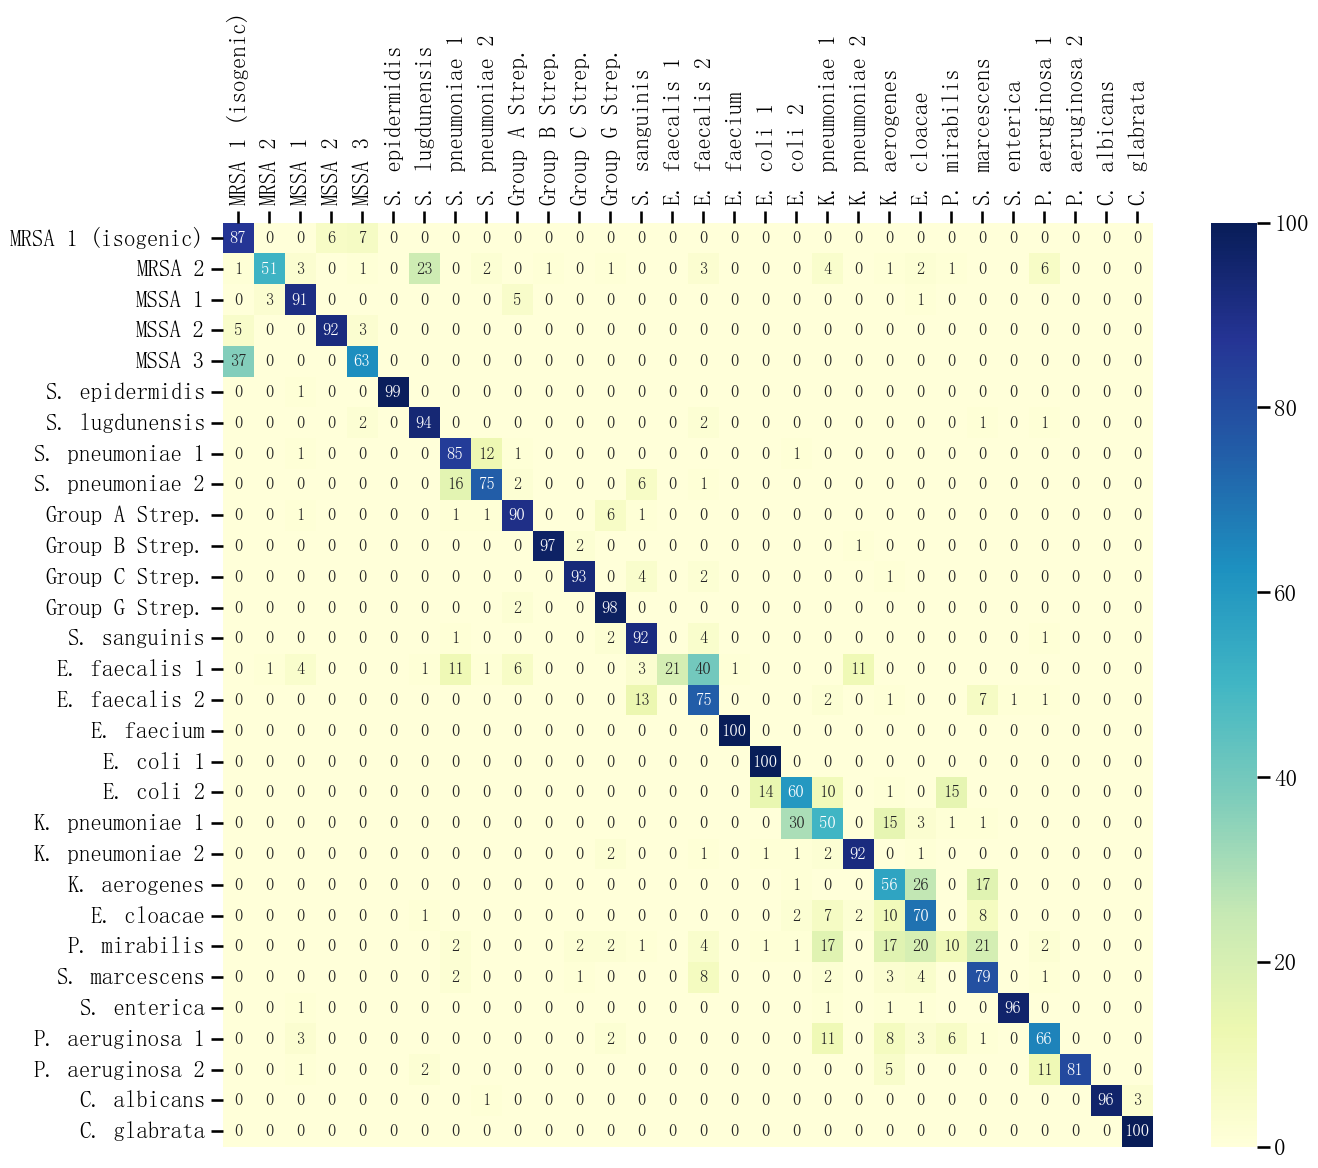

In [8]:
plot_confusion_matrix(y_test, y_pred)  # 预测结果的confusion_matrix图

## 2 使用预处理数据进行训练预测
对train与test数据集进行光滑去噪、基线化后再训练与预测。

In [5]:
from scipy.signal import savgol_filter
from pybaselines import Baseline


def sg_smooth(ys):
    # 定义窗口大小（必须是奇数）
    window_size = 11
    
    # 定义多项式的阶数
    polyorder = 3
    
    # 使用savgol_filter函数计算窗口移动多项式平滑
    ysn = savgol_filter(ys, window_length=window_size, polyorder=polyorder)
    return ysn


def airpls_baseline(ys, x=None):
    # Baseline对象需要x轴坐标, 此时利用ys数组最后一个维度的长度(Feature的个数)生成了一个伪坐标[0, 1, 2, ..., ]
    # (由于Raman中波数基本等间隔，因此这个坐标与实际坐标线性一一映射)
    if x is None:
        x = list(range(ys.shape[-1]))
    baseline_fitter = Baseline(x_data=x) 

    ys_airpls = []
    for y in ys:
        bkg, params = baseline_fitter.airpls(y, lam=1e5) #自适应加权惩罚最小二乘法（lam 越大基线越平滑；返回的 bkg 即估计出的荧光背景）
        ys_airpls.append(y - bkg)
    return np.array(ys_airpls)

## 2.1 先平滑再基线

In [18]:
# 对X_train数据进行savgol平滑与airpls降噪
X_train_sg = sg_smooth(X_train)  # 第一步：Savitzky-Golay 平滑去高频噪声
X_train_airpls = airpls_baseline(X_train_sg)  # 第二步：airPLS 基线校正（扣除荧光背景）

# 对X_test数据进行savgol平滑与airpls降噪
X_test_sg = sg_smooth(X_test)  # 测试集做完全相同的预处理
X_test_airpls = airpls_baseline(X_test_sg)  # 与训练集相同的处理顺序

In [16]:
from sklearn.model_selection import cross_validate

svm_clf = SVC(kernel='linear')  # 仍用线性核 SVM
# 进行交叉验证并返回每个折中的模型
cv_results = cross_validate(svm_clf, X_train_airpls, y_train, cv=5,   # 用“先平滑再基线”处理后的训练集做 5 折交叉验证
                            return_train_score=True, 
                            return_estimator=True)
cv_results

{'fit_time': array([1.71928596, 1.76044607, 1.58120322, 1.65684748, 1.97198892]),
 'score_time': array([1.99242043, 1.55059171, 1.48696828, 1.44316792, 1.88157701]),
 'estimator': [SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear'),
  SVC(kernel='linear')],
 'test_score': array([0.91333333, 0.94166667, 0.91666667, 0.93333333, 0.90666667]),
 'train_score': array([1.        , 1.        , 1.        , 1.        , 0.99958333])}

In [27]:
# ts = [0.91333333, 0.94166667, 0.91666667, 0.93333333, 0.90666667]
ts = cv_results['test_score']
print("In train dataset, model accuracy is {:.4f} (+/- {:.4f}) ".format(np.mean(ts), 2* np.std(ts)))  # 输出预处理后的 5 折平均准确率 ± 2 倍标准差

In train dataset, model accuracy is 0.9223 (+/- 0.0261) 


In [17]:
# 获取每个折中训练的模型
estimators = cv_results['estimator']
# 找到测试分数最高的模型
best_estimator = max(estimators, key=lambda e: cv_results['test_score'][estimators.index(e)])
# 预测测试集
y_pred = best_estimator.predict(X_test_airpls)  # 注意：测试集也必须用同样的预处理结果
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")

classification_report_result = classification_report(y_test, y_pred, digits=3, zero_division=0)
print(classification_report_result)

Accuracy: 0.789
              precision    recall  f1-score   support

         0.0      1.000     0.970     0.985       100
         1.0      0.971     1.000     0.985       100
         2.0      0.470     0.700     0.562       100
         3.0      0.853     0.990     0.917       100
         4.0      0.712     0.520     0.601       100
         5.0      0.971     1.000     0.985       100
         6.0      1.000     0.090     0.165       100
         7.0      0.478     0.760     0.587       100
         8.0      0.657     0.670     0.663       100
         9.0      0.410     0.550     0.470       100
        10.0      0.976     0.800     0.879       100
        11.0      0.353     0.120     0.179       100
        12.0      0.689     0.730     0.709       100
        13.0      0.971     0.680     0.800       100
        14.0      0.916     0.980     0.947       100
        15.0      0.859     0.670     0.753       100
        16.0      0.717     0.910     0.802       100
        17.

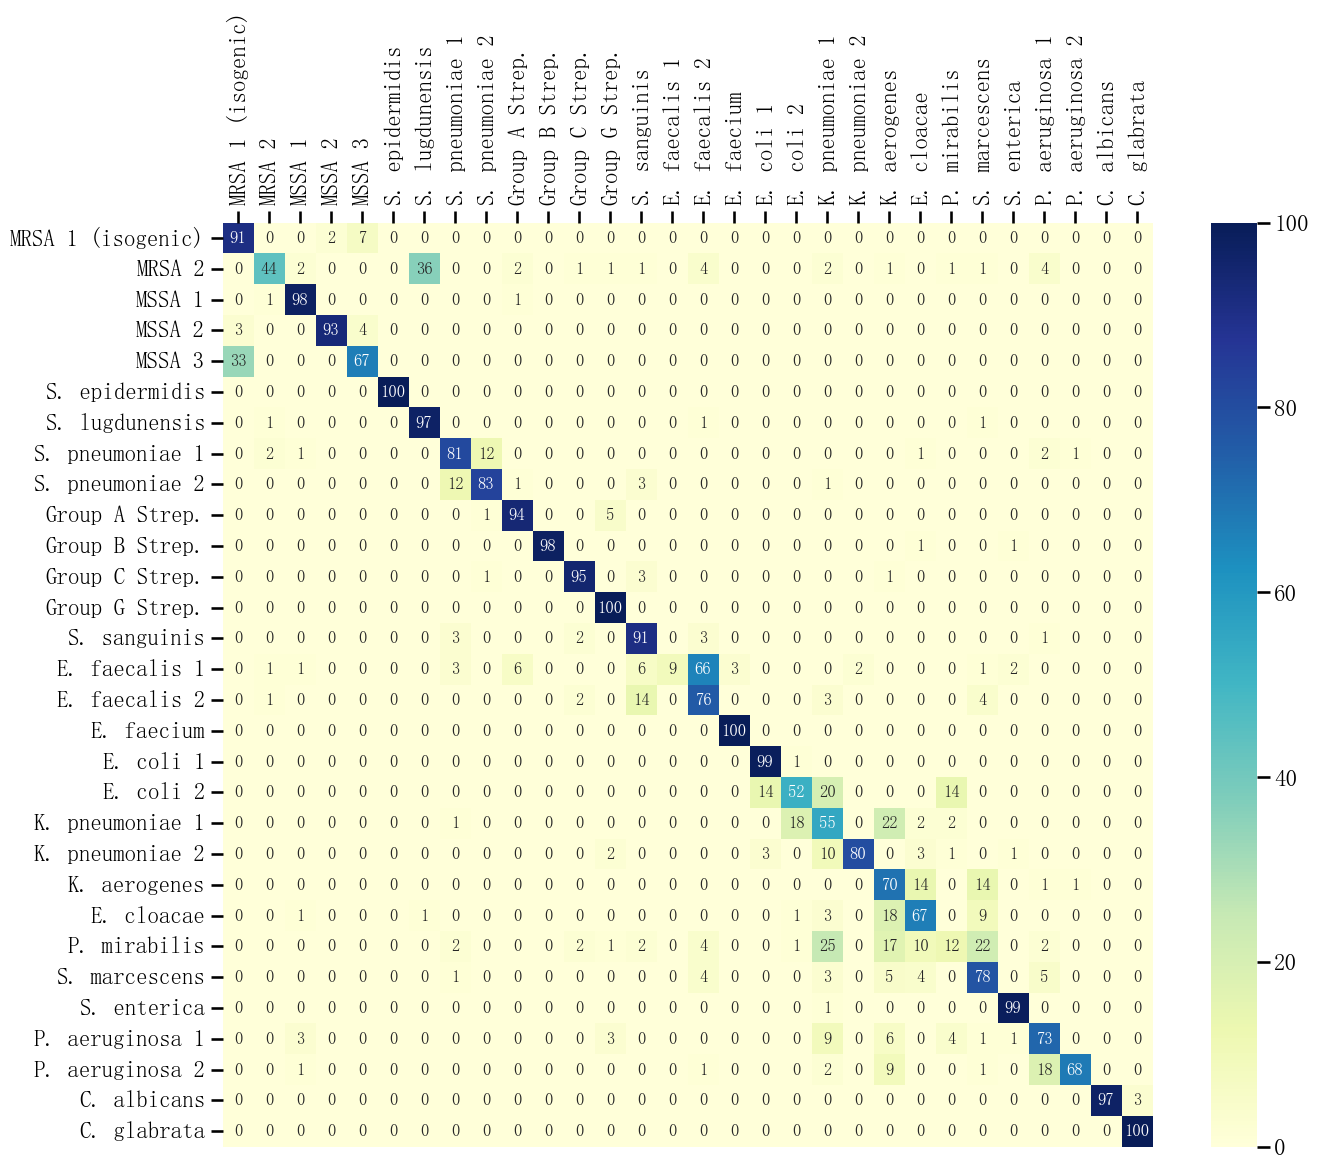

In [18]:
plot_confusion_matrix(y_test, y_pred)  # “先平滑再基线”方案的混淆矩阵

## 2.1 先基线再平滑

In [22]:
X_train_ag = sg_smooth(airpls_baseline(X_train))  # 与 2.1 相反：先 airPLS 基线校正，再做 SG 平滑
X_test_ag = sg_smooth(airpls_baseline(X_test))  # 测试集同样处理

svm_clf = SVC(kernel='linear')
# 进行交叉验证并返回每个折中的模型
cv_results = cross_validate(svm_clf, X_train_ag, y_train, cv=5,   # 用“先基线再平滑”的数据做 5 折交叉验证
                            return_train_score=True, 
                            return_estimator=True)
ts = cv_results['test_score']
print("In train dataset, model accuracy is {:.4f} (+/- {:.4f}) ".format(np.mean(ts), 2* np.std(ts)))  # 输出平均准确率 ± 2 倍标准差

In train dataset, model accuracy is 0.9300 (+/- 0.0271) 


In [23]:
# 获取每个折中训练的模型
estimators = cv_results['estimator']
# 找到测试分数最高的模型
best_estimator = max(estimators, key=lambda e: cv_results['test_score'][estimators.index(e)])
# 预测测试集
y_pred = best_estimator.predict(X_test_ag)  # 在同样预处理的测试集上预测
# 计算准确率
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")

classification_report_result = classification_report(y_test, y_pred, digits=3, zero_division=0)
print(classification_report_result)

Accuracy: 0.805
              precision    recall  f1-score   support

         0.0      1.000     0.950     0.974       100
         1.0      0.952     1.000     0.976       100
         2.0      0.583     0.630     0.606       100
         3.0      0.926     1.000     0.962       100
         4.0      0.643     0.450     0.529       100
         5.0      0.952     1.000     0.976       100
         6.0      0.938     0.150     0.259       100
         7.0      0.561     0.830     0.669       100
         8.0      0.621     0.820     0.707       100
         9.0      0.451     0.640     0.529       100
        10.0      0.944     0.840     0.889       100
        11.0      0.371     0.130     0.193       100
        12.0      0.760     0.760     0.760       100
        13.0      0.988     0.820     0.896       100
        14.0      0.891     0.980     0.933       100
        15.0      0.813     0.610     0.697       100
        16.0      0.692     0.900     0.783       100
        17.

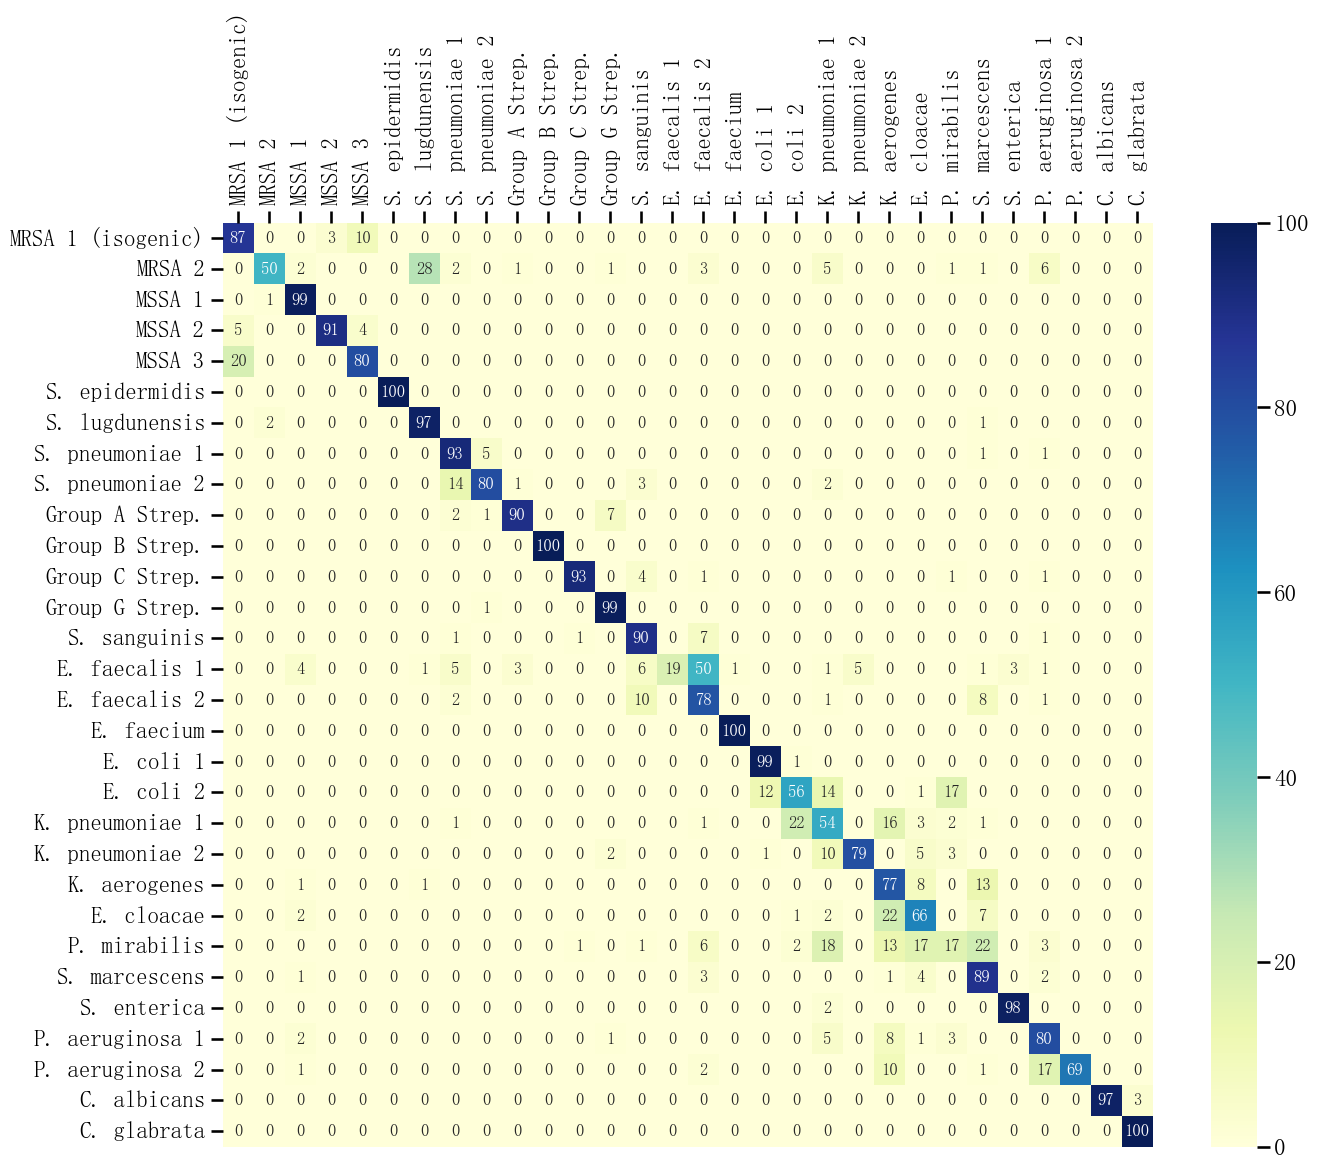

In [33]:
plot_confusion_matrix(y_test, y_pred)  # “先基线再平滑”方案的混淆矩阵

**从结果上来看，先基线化再平滑化，模型效果会更好。实际上一般ML时，无论前面处理时是否做过平滑，在最后再来一次平滑可能效果更好。**

## 3 其他

In [10]:
import pandas as pd
import numpy as np
# 滑动平均（卷积）平滑：用窗口内均值代替中心点，压制随机噪声
def convolve_smooth_transform(data, k=51):
    def convolve_transform(row):
        pad_width = k // 2  # 两侧各填充约 k/2 个点，保证卷积后长度不变
        row = np.pad(row, (pad_width, k - pad_width - 1), mode='edge')  # mode='edge'：用边缘值填充
        row = np.convolve(row, np.ones(k) / k, mode='valid')  # 与长度 k 的均匀核做卷积，取 valid 部分恢复原长度
        return row
    return np.apply_along_axis(convolve_transform, arr=data, axis=-1)  # 对每条光谱（最后一维）逐行应用

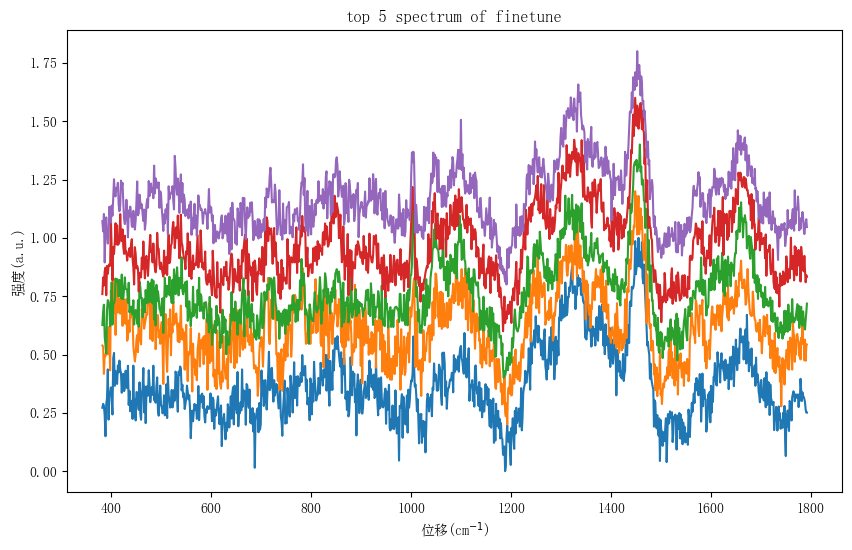

In [3]:
from utils import plot_spectra
x_f = './data/wavenumbers.npy'
x = np.load(x_f)  # 拉曼位移（波数）坐标，作图横轴

# 载入finetune数据集
X_f = './data/X_finetune.npy'
y_f = './data/y_finetune.npy'
X_train = np.load(X_f)  # 重新载入原始（未预处理）训练集用于对比展示
y_train = np.load(y_f)

plot_spectra(x, X_train[:5], 'top 5 spectrum of finetune',  dy=0.2)  # 原始光谱

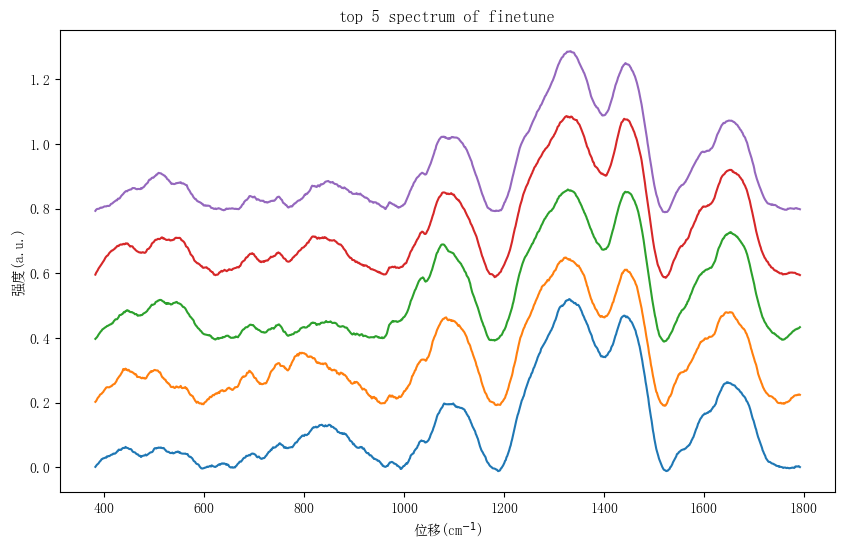

In [61]:
plot_spectra(x, airpls_baseline_transform(convolve_smooth_transform(X_train[:5], k=51)), 'top 5 spectrum of finetune',  dy=0.2)  # 卷积平滑 + airPLS 基线校正

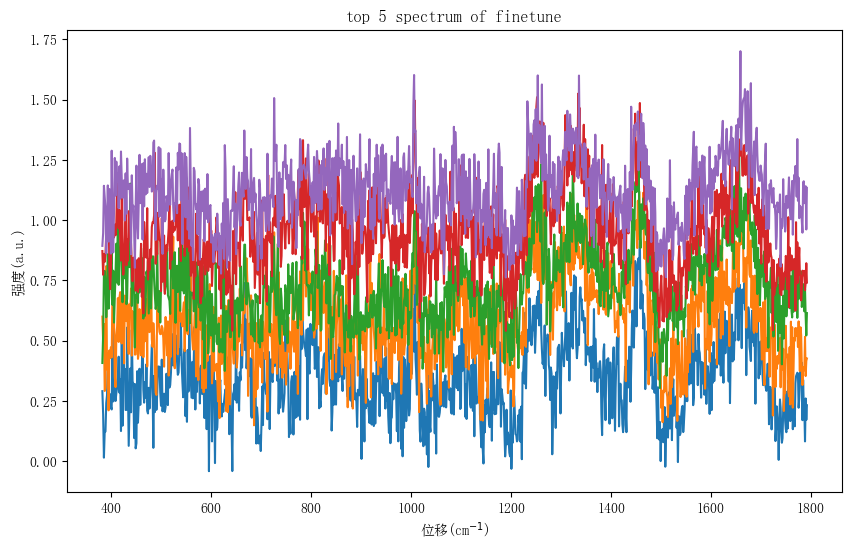

In [59]:
plot_spectra(x, airpls_baseline_transform(X_train[-5:]), 'top 5 spectrum of finetune',  dy=0.2)  # 仅 airPLS 基线校正

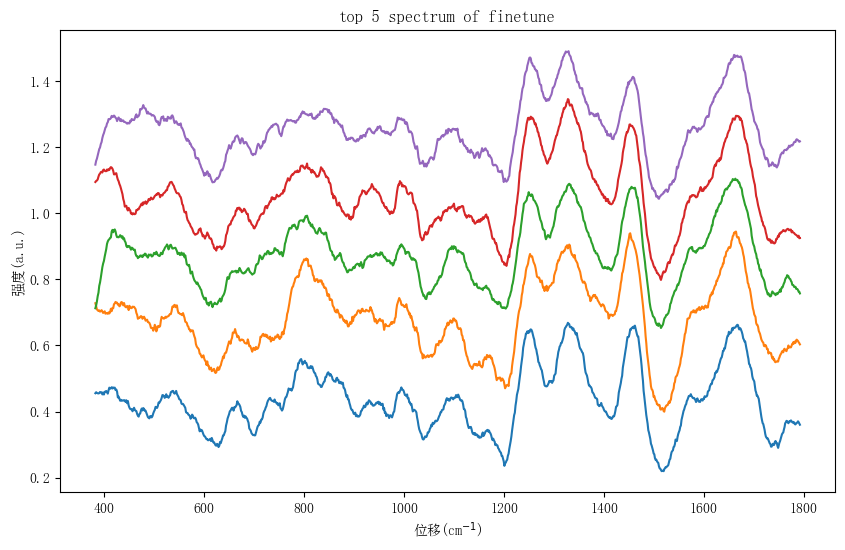

In [18]:
plot_spectra(x, convolve_smooth_transform(X_train[-5:], k=31), 'top 5 spectrum of finetune',  dy=0.2)  # 仅卷积平滑（k=31）

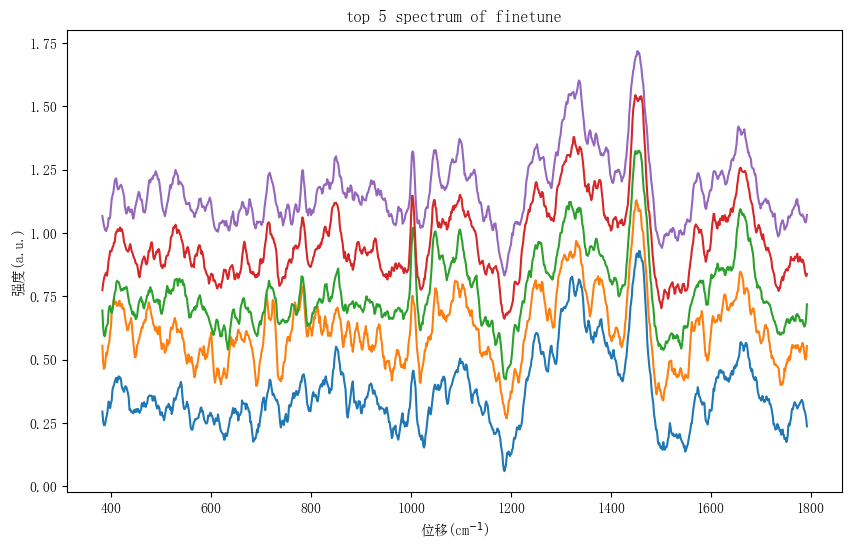

In [7]:
plot_spectra(x, sg_smooth(X_train[:5]), 'top 5 spectrum of finetune',  dy=0.2)  # 仅 SG 平滑

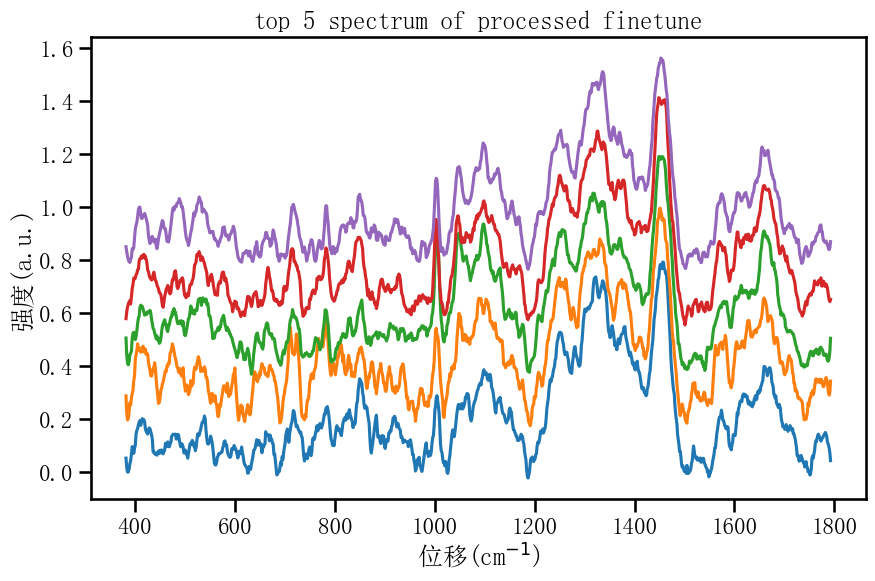

In [13]:
plot_spectra(x, X_train_airpls[:5], 'top 5 spectrum of processed finetune',  dy=0.2)  # 2.1 节处理结果：先 SG 平滑再 airPLS

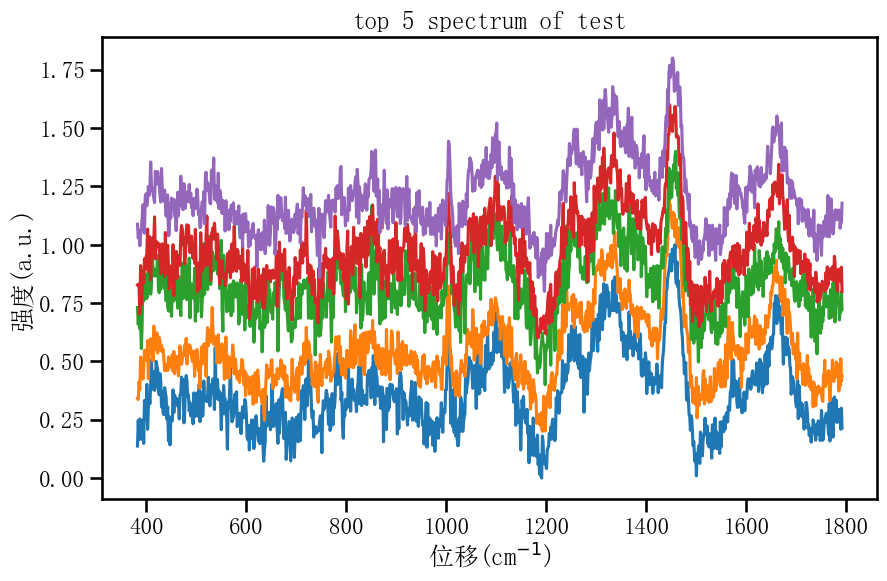

In [14]:
plot_spectra(x, convolve_smooth_transform(X_test[:5]), 'top 5 spectrum of test',  dy=0.2)  # 测试集：卷积平滑

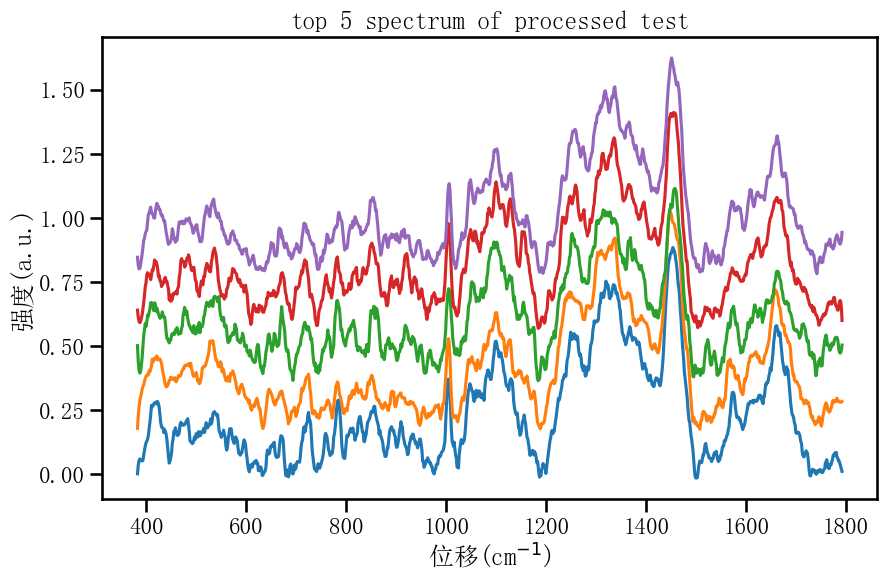

In [15]:
plot_spectra(x, X_test_airpls[:5], 'top 5 spectrum of processed test',  dy=0.2)  # 测试集：2.1 节处理结果

# 4 作业
实际上面有许多代码块重复多次，应提取至函数中，这样如果发生修改时只需要修改一处而不需多处修改（多处修改易遗漏且麻烦）。  
1) 请把上面重复代码提取到函数方法中，并能使代码可通。(可以先复制本代码文件，并在复制后的文件中修改)
2) 使用其它ML的模型，看能否提升test数据集上的准确率

In [58]:
import numpy as np
from pybaselines.whittaker import airpls
from pybaselines import Baseline

def airpls_baseline_transform(data):  # 向量化版 airPLS 基线校正（对最后一维逐行处理）
    def airpls_transform(row):
        bkg = airpls(row, lam=1e5)[0]  # 估计基线并从原信号中扣除
        return row - bkg

    return np.apply_along_axis(airpls_transform, arr=data, axis=-1)
    
# 创建一个二维数组作为示例数据
data = np.random.rand(2, 200)  # 100行，200列

# 对数据进行基线校正，axis=-1表示沿着列（最后一个轴）进行处理
corrected_data = airpls_baseline_transform(data)  # 用随机数据演示基线校正效果
#corrected_data = airpls(data[0])

# 查看校正后的数据
print(corrected_data)

[[ 0.84705237  0.54934589  0.85875748  0.19619946  0.64254507  0.49329973
   0.68009695  0.93745166  0.06117677  0.46818549  0.59380413  0.76641825
   0.41070505  0.79376545  0.72729565  0.40175261  0.77380462 -0.01775567
   0.44163815  0.17693642  0.36458054  0.38406381  0.66732245  0.52616473
   0.79297161  0.87945737  0.3552346   0.81637902  0.71775388  0.07382552
   0.24692202  0.14199173  0.85680495  0.04983755  0.35430322  0.74943054
   0.07594671  0.62761398  0.41858015  0.52370543  0.36198135  0.02367353
   0.19501364  0.84042309  0.46718754  0.44696976  0.81384487  0.02902531
   0.43059325  0.0880909   0.18031659  0.47351589  0.90046493  0.4287578
   0.6388457   0.22003517  0.83432372  0.73393672  0.88862866  0.66668272
   0.75785129  0.45076835  0.32706727  0.58921814  0.52137765  0.11176709
   0.00970422  0.32219133  0.17019942  0.56592964  0.38088632  0.69973226
   0.56577705  0.9253856   0.65171168  0.4237155   0.37215195  0.51651188
   0.60191554  0.42176094  0.14252177  